# Online Shoppers Purchasing Intention Prediction

## 1. Project Introduction

This project aims to develop a Machine Learning
model that predicts whether an online shopper
will make a purchase during a website session.

The project uses the Online Shoppers Purchasing
Intention Dataset from the UCI Machine Learning
Repository.

This is a Binary Classification problem.

The target variable is Revenue:
- True: The visitor makes a purchase.
- False: The visitor does not make a purchase.

Three Machine Learning algorithms will be
implemented and compared.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

# Additional tools
from sklearn.base import clone

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


Load your dataset

In [2]:
df = pd.read_csv("Dataset/online_shoppers_intention.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Data Cleaning – Removing Duplicate Records

In this step, duplicate records are identified and removed
from the dataset.

Duplicate records are identical rows that contain the same
information across all columns.

Removing exact duplicate records helps prevent repeated
observations from unnecessarily influencing the analysis
and model training.

Display the first five records

Insert the duplicate removal code

In [3]:
# Step 1: Count duplicate records before removal
duplicates_before = df.duplicated().sum()

print("Duplicate records before cleaning:", duplicates_before)


# Step 2: Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)


# Step 3: Count duplicate records after removal
duplicates_after = df.duplicated().sum()


# Step 4: Display cleaning results
print("Duplicate records removed:", duplicates_before)

print("Duplicate records after cleaning:", duplicates_after)

print("Dataset shape after cleaning:", df.shape)

Duplicate records before cleaning: 125
Duplicate records removed: 125
Duplicate records after cleaning: 0
Dataset shape after cleaning: (12205, 18)


In [4]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Find the number of rows and columns

In [5]:
print("Dataset Shape:", df.shape)

print("Number of Rows:", df.shape[0])

print("Number of Columns:", df.shape[1])

Dataset Shape: (12205, 18)
Number of Rows: 12205
Number of Columns: 18


Understand all columns

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRelated_Duration  12205 non-null  float64
 6   BounceRates              12205 non-null  float64
 7   ExitRates                12205 non-null  float64
 8   PageValues               12205 non-null  float64
 9   SpecialDay               12205 non-null  float64
 10  Month                    12205 non-null  str    
 11  OperatingSystems         12205 non-null  int64  
 12  Browser                  12205 non-null  int64  
 13  Region                   12205 non-null  int64  
 14  TrafficType              12205 no

display statistical information

In [7]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,2.124211,2.357804,3.153298,4.073904
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,0.906823,1.710114,2.402340,4.016654
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


Check missing values

In [8]:
missing_values = df.isnull().sum()

print(missing_values)

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


Check duplicate records

In [9]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


Understand the target variable

In [10]:
print(df["Revenue"].value_counts())

Revenue
False    10297
True      1908
Name: count, dtype: int64


In [11]:
print(df["Revenue"].value_counts(normalize=True) * 100)

Revenue
False    84.367063
True     15.632937
Name: proportion, dtype: float64


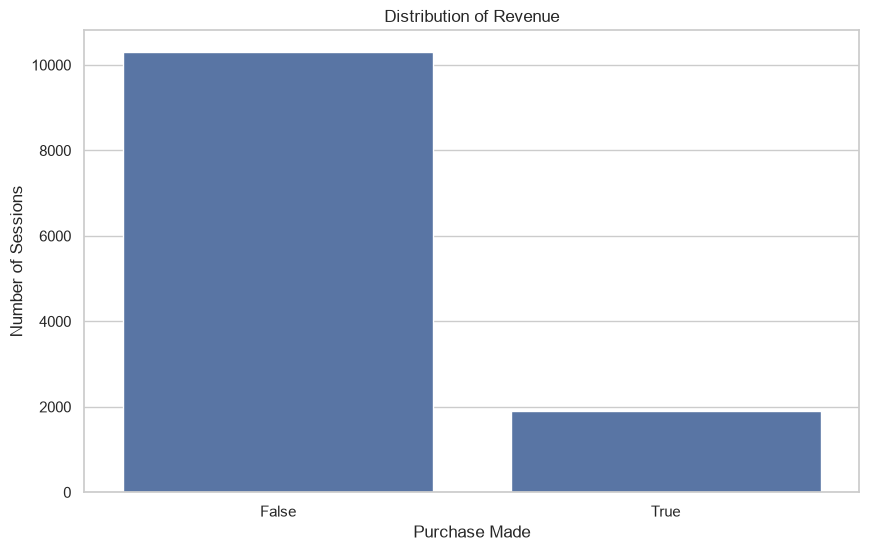

In [12]:
sns.countplot(data=df, x="Revenue")

plt.title("Distribution of Revenue")
plt.xlabel("Purchase Made")
plt.ylabel("Number of Sessions")

plt.show()

Understand the features

Exploratory Data Analysis (EDA)

Analyze numerical features

In [13]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

print(numerical_columns)

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType'],
      dtype='str')


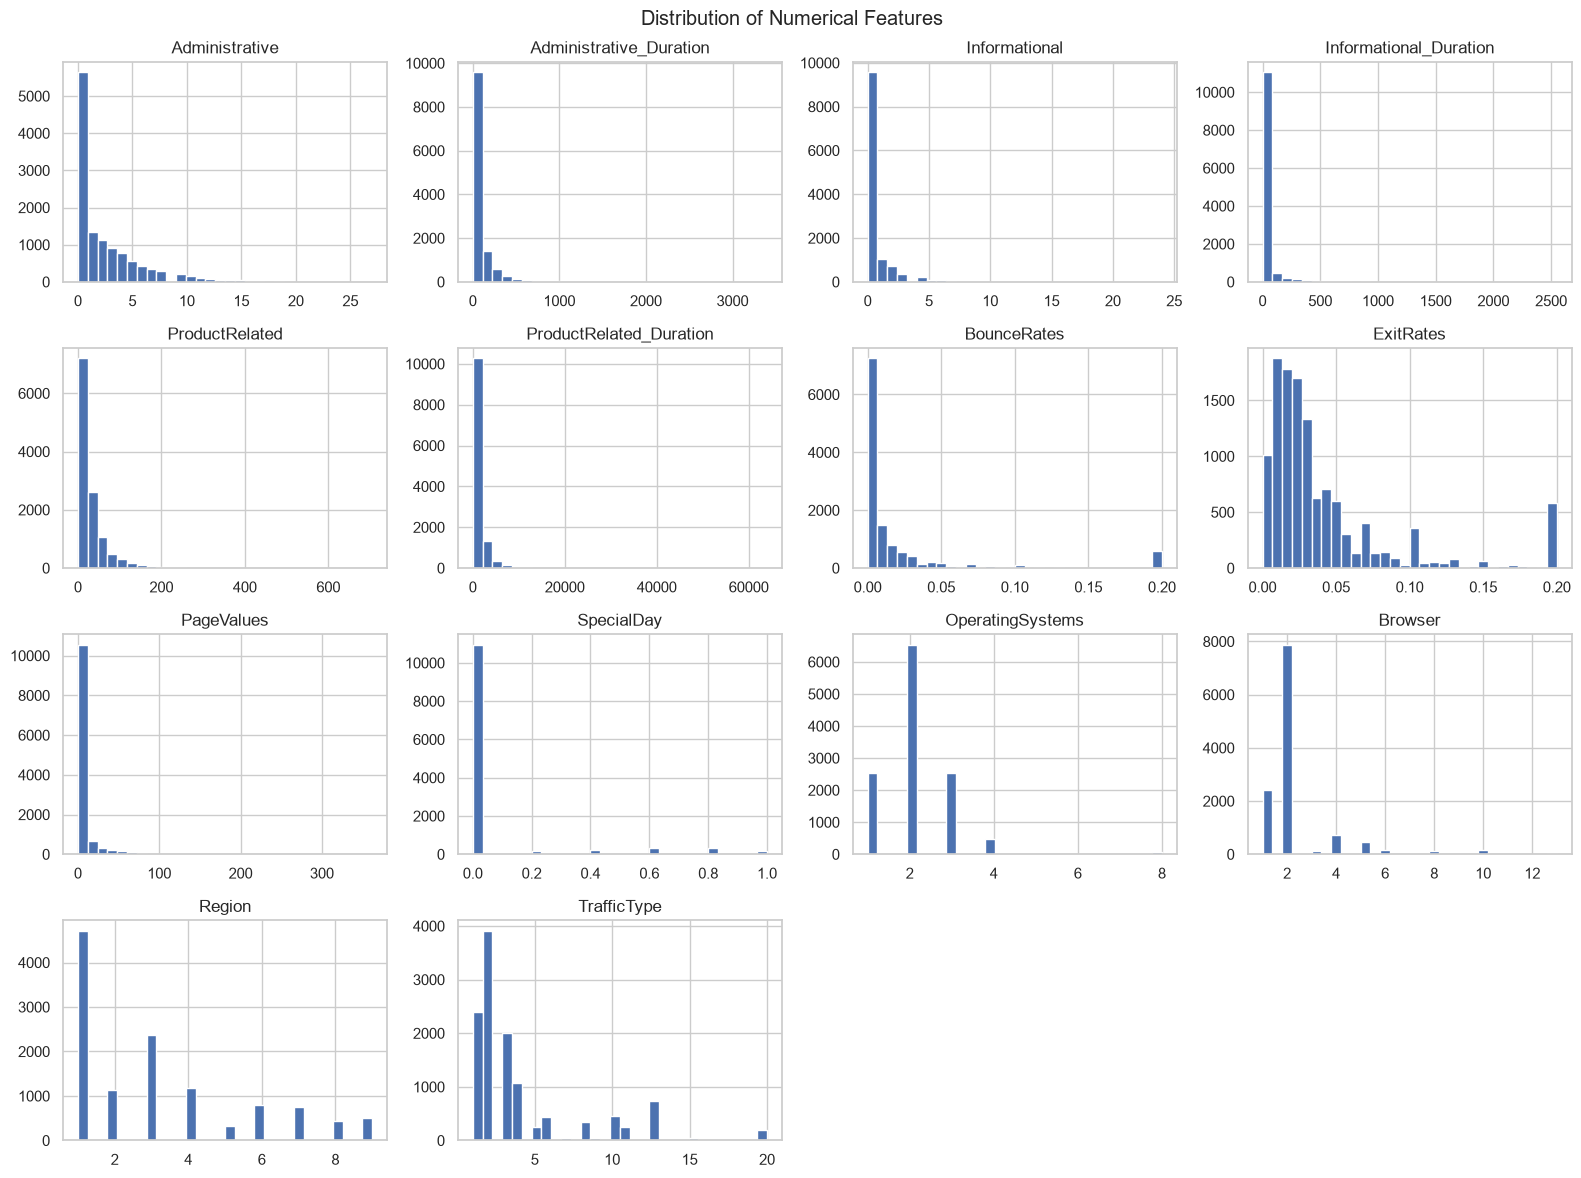

In [14]:
df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle("Distribution of Numerical Features")

plt.tight_layout()

plt.show()

Analyze categorical features

In [15]:
categorical_columns = df.select_dtypes(
    include=["object", "bool"]
).columns

print(categorical_columns)

Index(['Month', 'VisitorType', 'Weekend', 'Revenue'], dtype='str')


C:\Users\Sharma\AppData\Local\Temp\ipykernel_10648\849952476.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


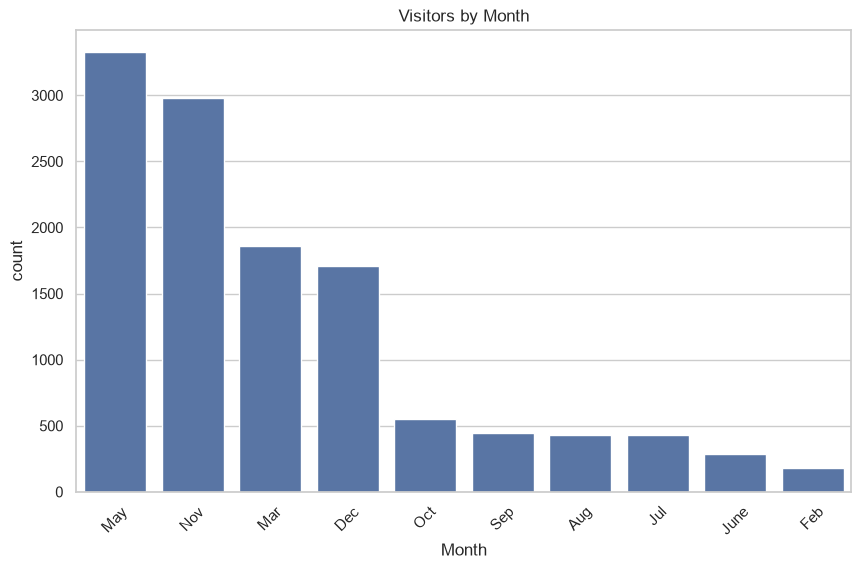

In [16]:
sns.countplot(
    data=df,
    x="Month",
    order=df["Month"].value_counts().index
)

plt.title("Visitors by Month")
plt.xticks(rotation=45)

plt.show()

Correlation heatmap

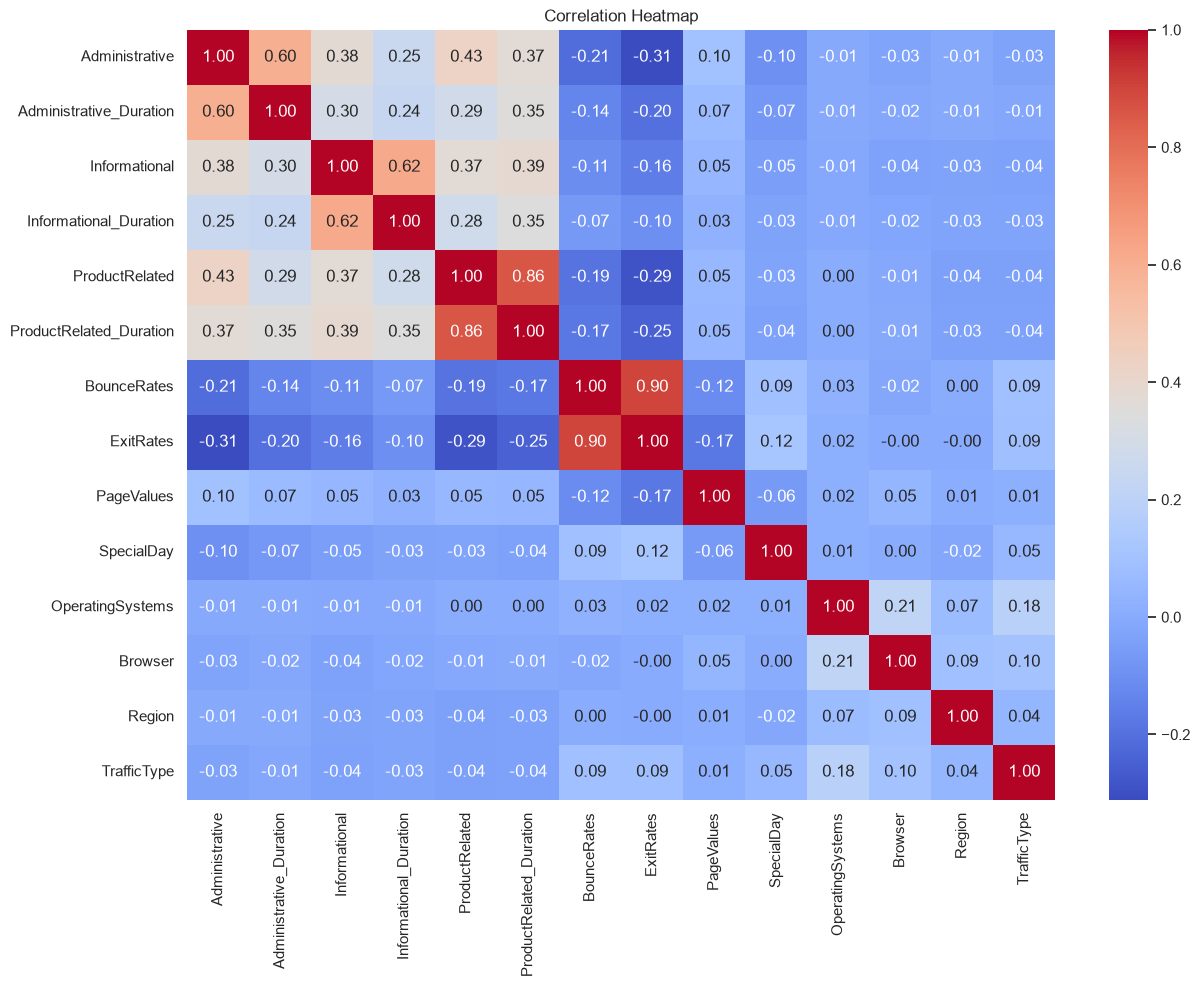

In [17]:
plt.figure(figsize=(14, 10))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Compare Revenue with other features

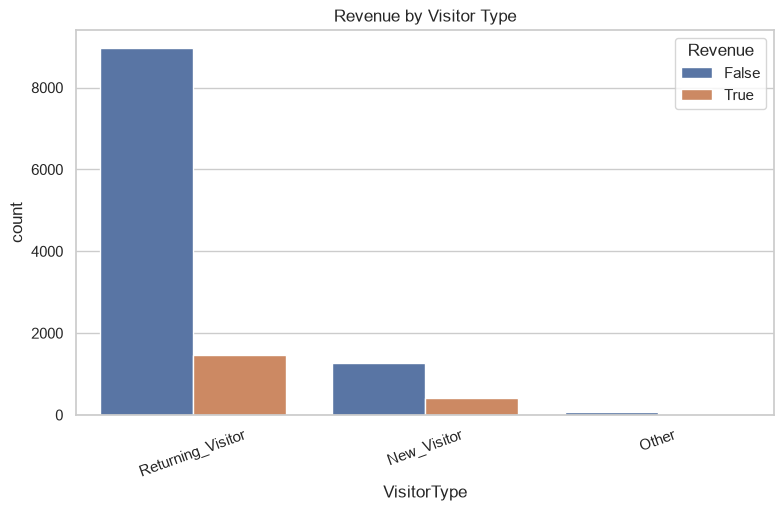

In [18]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="VisitorType",
    hue="Revenue"
)

plt.title("Revenue by Visitor Type")
plt.xticks(rotation=20)

plt.show()

Now compare revenue by month

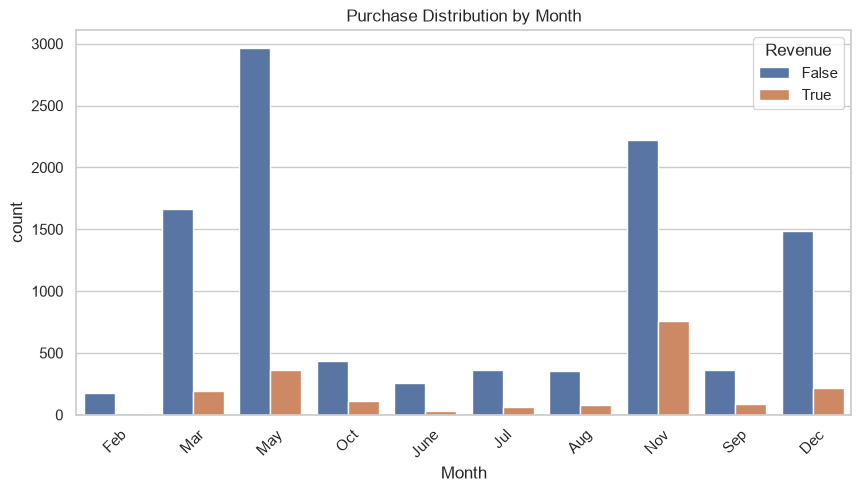

In [19]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Month",
    hue="Revenue"
)

plt.title("Purchase Distribution by Month")
plt.xticks(rotation=45)

plt.show()

Analyze possible outliers

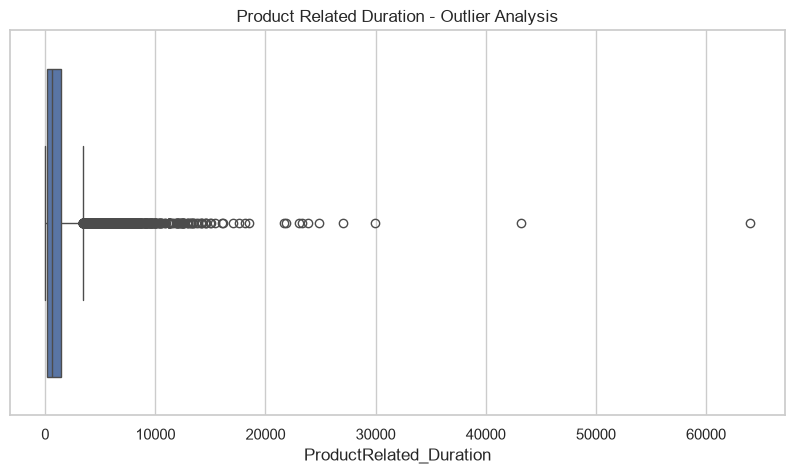

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="ProductRelated_Duration")

plt.title("Product Related Duration - Outlier Analysis")

plt.show()

Data Preprocessing

Separate input features and target variable

In [21]:
X = df.drop("Revenue", axis=1)

y = df["Revenue"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (12205, 17)
Target Shape: (12205,)


Identify numerical and categorical columns

In [22]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Categorical Features:
['Month', 'VisitorType', 'Weekend']


C:\Users\Sharma\AppData\Local\Temp\ipykernel_10648\1435108896.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


Prepare numerical and categorical data

In [23]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Split the dataset into training and testing

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (9764, 17)
Testing Features: (2441, 17)
Training Target: (9764,)
Testing Target: (2441,)


Machine Learning Model Implementation

We will implement three algorithms.
1. Logistic Regression.
2. Decision Tree Classifier.
3. Random Forest Classifier.

Create the Logistic Regression model

In [25]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


Create the Decision Tree model

In [26]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            max_depth=10,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


Create the Random Forest model

In [27]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


Make predictions

In [28]:
logistic_predictions = logistic_model.predict(X_test)

decision_tree_predictions = decision_tree_model.predict(X_test)

random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions completed!")

Predictions completed!


displaying some predictions

In [29]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions
})

comparison.head(10)

,Actual,Logistic Regression,Decision Tree,Random Forest
11640,False,False,False,False
6936,False,False,False,False
7194,False,False,False,False
11263,False,False,False,False
4728,False,False,False,False
9878,False,True,True,True
8101,False,False,False,False
6642,False,False,False,False
10215,False,False,False,False
10224,False,False,False,False


Model Evaluation

Create an evaluation function

In [30]:
def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test, probabilities
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    }

Evaluate all three models

In [31]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

results = {}

for name, model in models.items():

    results[name] = evaluate_model(
        model,
        X_test,
        y_test
    )

results_df = pd.DataFrame(results).T

results_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.851290,0.516351,0.785340,0.623053,0.910902
Decision Tree,0.860303,0.538462,0.751309,0.627322,0.855079
Random Forest,0.898402,0.678191,0.667539,0.672823,0.927230


Visualize model comparison

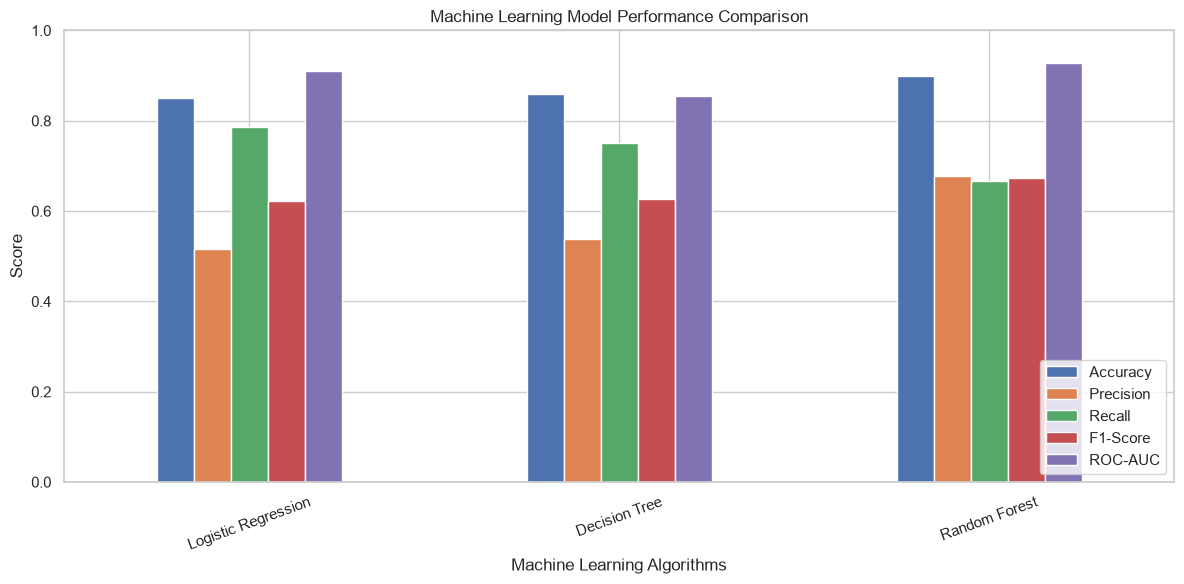

In [32]:
results_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")

plt.ylabel("Score")

plt.xlabel("Machine Learning Algorithms")

plt.xticks(rotation=20)

plt.ylim(0, 1)

plt.legend(
    loc="lower right"
)

plt.tight_layout()

plt.show()

Create confusion matrices

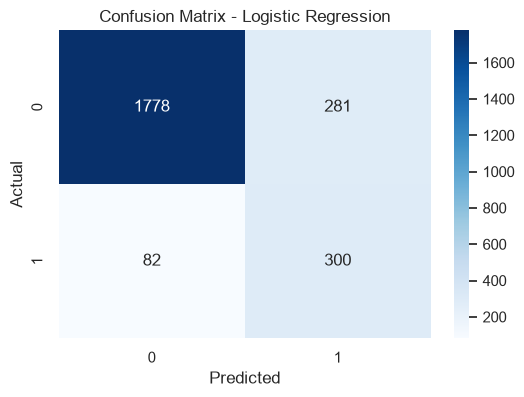

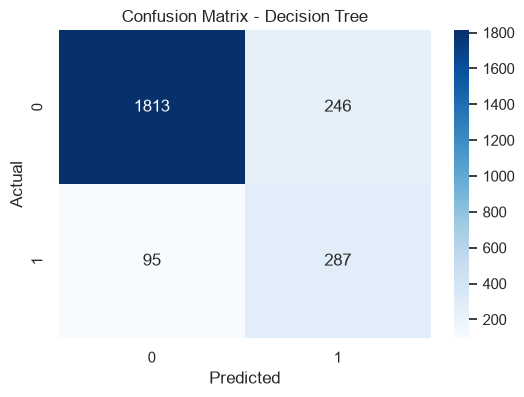

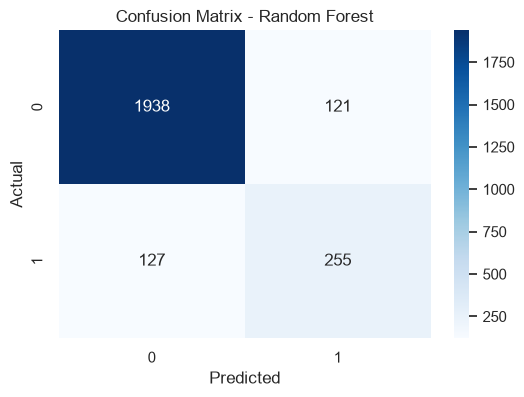

In [33]:
for name, model in models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions
    )

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")

    plt.xlabel("Predicted")

    plt.ylabel("Actual")

    plt.show()

Classification report

In [34]:
for name, model in models.items():

    predictions = model.predict(X_test)

    print("\n", "=" * 50)

    print(name)

    print("=" * 50)

    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

       False       0.96      0.86      0.91      2059
        True       0.52      0.79      0.62       382

    accuracy                           0.85      2441
   macro avg       0.74      0.82      0.77      2441
weighted avg       0.89      0.85      0.86      2441


Decision Tree
              precision    recall  f1-score   support

       False       0.95      0.88      0.91      2059
        True       0.54      0.75      0.63       382

    accuracy                           0.86      2441
   macro avg       0.74      0.82      0.77      2441
weighted avg       0.89      0.86      0.87      2441


Random Forest
              precision    recall  f1-score   support

       False       0.94      0.94      0.94      2059
        True       0.68      0.67      0.67       382

    accuracy                           0.90      2441
   macro avg       0.81      0.80      0.81      2441
weighted avg       0.90

ROC curves

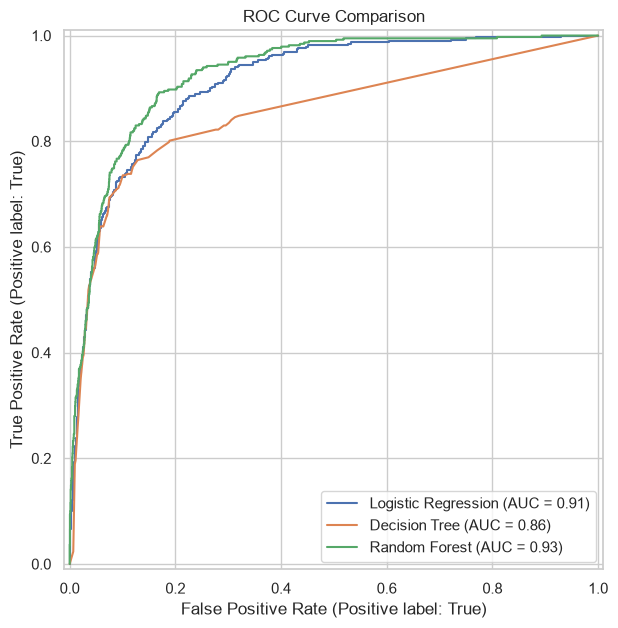

In [35]:
plt.figure(figsize=(9, 7))

for name, model in models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=plt.gca()
    )

plt.title("ROC Curve Comparison")

plt.show()

Identify the best model

In [36]:
best_model_name = results_df["F1-Score"].idxmax()

best_model = models[best_model_name]

print("Best Model:", best_model_name)

print(
    "Best F1-Score:",
    results_df.loc[best_model_name, "F1-Score"]
)

Best Model: Random Forest
Best F1-Score: 0.6728232189973615


Feature importance

In [37]:
rf_classifier = random_forest_model.named_steps["classifier"]

rf_preprocessor = random_forest_model.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
8,num__PageValues,0.406445
7,num__ExitRates,0.094710
5,num__ProductRelated_Duration,0.083929
4,num__ProductRelated,0.063236
6,num__BounceRates,0.050765
1,num__Administrative_Duration,0.045962
0,num__Administrative,0.037686
21,cat__Month_Nov,0.032157
13,num__TrafficType,0.024654
12,num__Region,0.022765


Visualize:

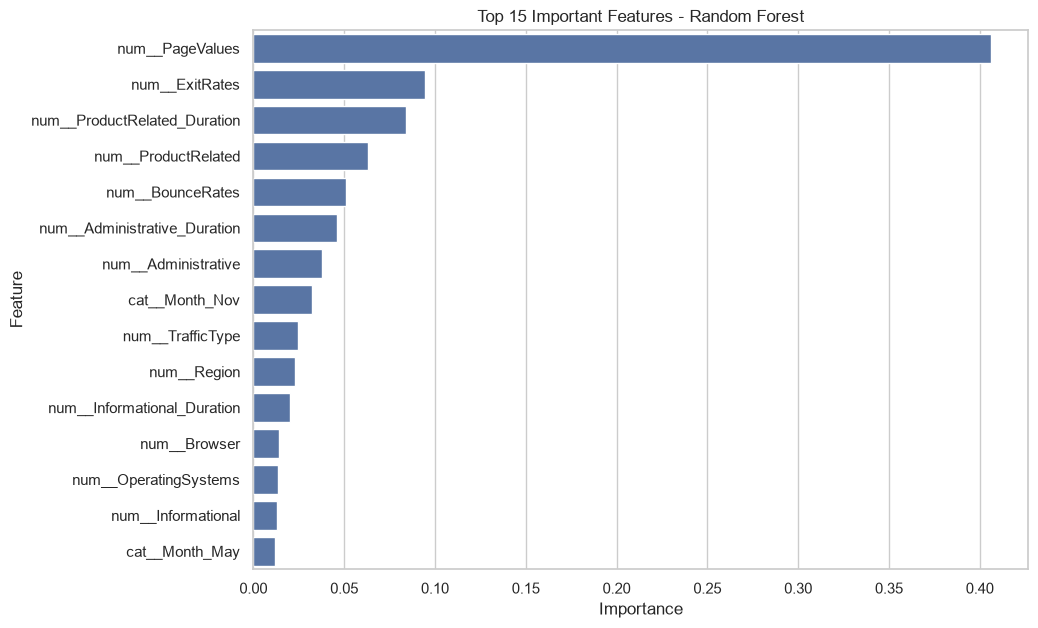

In [38]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")

plt.show()

# Conclusion

In this project, we developed a Machine Learning
system to predict online shoppers' purchasing
intentions.

We explored the dataset, performed data cleaning
and preprocessing, and conducted Exploratory
Data Analysis.

Three Machine Learning algorithms were
implemented:

1. Logistic Regression
2. Decision Tree
3. Random Forest

The models were evaluated using accuracy,
precision, recall, F1-score and ROC-AUC.

Based on the evaluation results, the best
performing model was identified.

The project demonstrates how Machine Learning
can help e-commerce businesses understand
customer purchasing behavior.